# LDFormer: NHD Training and RESIDE / reside-6k Testing
A Kaggle-ready lightweight dehazing Transformer notebook that mirrors `nhdv2`. Default settings are sized for a 15 GB Kaggle GPU.


## Setup Dependencies


In [1]:
%%capture
!pip -q install torchmetrics scikit-image --root-user-action=ignore


## Imports and Warning Control


In [2]:
import os
# Set before CUDA/PyTorch initialization; restart the Kaggle kernel, then Run All.
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
import json
import random
import warnings
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


## Configuration
Update only the dataset paths if your Kaggle input slugs differ. The required folder layout is unchanged from `nhdv2`.


In [3]:
@dataclass
class CFG:
    # NHD structure: ROOT/dataset_index.json and paths referenced by the index.
    ROOT: str = "/kaggle/input/datasets/mouryavardhanrathod/nhd-dataset-v1/NHD"
    INDEX_FILE: str = ""

    # Paired external tests must each contain hazy/ and gt/ folders.
    RESIDE_ROOT: str = "/kaggle/input/datasets/rathlavathramesh/reside/RESIDE_NHD/test"
    RESIDE6K_ROOT: str = "/kaggle/input/datasets/rathlavathramesh/reside-6k-dataset/test"

    # Kaggle-safe settings. The original paper reports 512x512 input; use 192 for a 15 GB GPU,
    # then set IMAGE_SIZE=512 and lower BATCH_SIZE further if the GPU permits it.
    IMAGE_SIZE: int = 192
    BATCH_SIZE: int = 1
    ACCUM_STEPS: int = 8
    MODEL_DIM: int = 24
    EPOCHS: int = 100
    LR: float = 2e-4
    WEIGHT_DECAY: float = 1e-4
    PATIENCE: int = 12
    NUM_WORKERS: int = 2
    SEED: int = 42
    OUT_DIR: str = "/kaggle/working/ldformer_nhd"
    SELECTED_STRATEGIES: tuple = ("uniform", "fog_bank", "perlin", "radial", "depth_dep")

cfg = CFG()
cfg.INDEX_FILE = os.path.join(cfg.ROOT, "dataset_index.json")
os.makedirs(cfg.OUT_DIR, exist_ok=True)
assert cfg.IMAGE_SIZE % 8 == 0, "Original LDFormer has three PixelUnshuffle stages; IMAGE_SIZE must be divisible by 8."
print("Output dir:", cfg.OUT_DIR)

Output dir: /kaggle/working/ldformer_nhd


## NHD Dataset Loader
NHD training/validation/test splits come from `dataset_index.json`. RESIDE and reside-6k use paired image folders for external evaluation.


In [4]:
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
image_transform = transforms.Compose([
    transforms.Resize((cfg.IMAGE_SIZE, cfg.IMAGE_SIZE)),
    transforms.ToTensor(),
])

def list_images(folder):
    if not folder or not os.path.isdir(folder):
        return []
    return sorted(
        os.path.join(root, name)
        for root, _, files in os.walk(folder)
        for name in files
        if name.lower().endswith(IMAGE_EXTENSIONS)
    )

def normalize_pair_stem(path):
    stem = os.path.splitext(os.path.basename(path))[0].lower()
    for token in ("_hazy", "-hazy", " haze", "_gt", "-gt", "_clean", "-clean", "_clear", "-clear"):
        stem = stem.replace(token, "")
    return stem

def build_image_pairs_from_folders(hazy_dir, gt_dir):
    hazy_paths, gt_paths = list_images(hazy_dir), list_images(gt_dir)
    gt_by_stem = {normalize_pair_stem(path): path for path in gt_paths}
    pairs = [(hazy, gt_by_stem[normalize_pair_stem(hazy)]) for hazy in hazy_paths if normalize_pair_stem(hazy) in gt_by_stem]
    return pairs or (list(zip(hazy_paths, gt_paths)) if len(hazy_paths) == len(gt_paths) else [])

def find_paired_root(preferred, alternatives):
    for root in (preferred, *alternatives):
        if os.path.isdir(os.path.join(root, "hazy")) and os.path.isdir(os.path.join(root, "gt")):
            return root
    return None

class PairedDehazeDataset(Dataset):
    def __init__(self, pairs, dataset_name):
        self.pairs, self.dataset_name = pairs, dataset_name

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        hazy_path, gt_path = self.pairs[idx]
        hazy = Image.open(hazy_path).convert("RGB")
        gt = Image.open(gt_path).convert("RGB")
        return {
            "hazy": image_transform(hazy),
            "gt": image_transform(gt),
            "dataset": self.dataset_name,
            "img_id": os.path.basename(hazy_path),
        }

def build_nhd_pairs(split):
    if not os.path.isfile(cfg.INDEX_FILE):
        raise FileNotFoundError(f"NHD index not found: {cfg.INDEX_FILE}")
    with open(cfg.INDEX_FILE, "r") as f:
        metadata = json.load(f)
    pairs = []
    for item in metadata:
        if item.get("split") != split or item.get("strategy") not in cfg.SELECTED_STRATEGIES:
            continue
        hazy = os.path.join(cfg.ROOT, item["hazy_path"])
        gt = os.path.join(cfg.ROOT, item["gt_path"])
        if os.path.isfile(hazy) and os.path.isfile(gt):
            pairs.append((hazy, gt))
    return pairs

train_dataset = PairedDehazeDataset(build_nhd_pairs("train"), "NHD_dataset")
val_dataset = PairedDehazeDataset(build_nhd_pairs("val"), "NHD_dataset")
test_dataset = PairedDehazeDataset(build_nhd_pairs("test"), "NHD_dataset")
assert len(train_dataset) and len(val_dataset) and len(test_dataset), "NHD split is empty; check cfg.ROOT."

def make_loader(dataset, shuffle=False):
    return DataLoader(dataset, batch_size=cfg.BATCH_SIZE, shuffle=shuffle, num_workers=cfg.NUM_WORKERS, pin_memory=torch.cuda.is_available())

train_loader, val_loader, test_loader = make_loader(train_dataset, True), make_loader(val_dataset), make_loader(test_dataset)
print(f"NHD pairs — train: {len(train_dataset)}, val: {len(val_dataset)}, test: {len(test_dataset)}")


NHD pairs — train: 560, val: 70, test: 70


## Original LDFormer Paper Architecture

This replaces the prior two-level Restormer-style U-Net with the published LDFormer topology: **3×3 projection → 3 TM → CAIM → encoder 2/4/8 TM → 16-TM central block → decoder 8/4/2 TM → 3 TM → CAIM → 3×3 reconstruction**.

It implements the paper-defined SFN, CAIM, PixelUnshuffle/PixelShuffle stages, and learned weighted 1×1 skip fusion. The paper does not publish the precise attention equation inside a transformer module; the notebook retains the efficient channel self-attention already used by the working notebook for that unspecified internal operation.

In [5]:
class LayerNorm2d(nn.Module):
    def __init__(self, channels, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(channels))
        self.bias = nn.Parameter(torch.zeros(channels))
        self.eps = eps

    def forward(self, x):
        mean = x.mean(1, keepdim=True)
        var = (x - mean).pow(2).mean(1, keepdim=True)
        x = (x - mean) / torch.sqrt(var + self.eps)
        return x * self.weight[:, None, None] + self.bias[:, None, None]


class SelectiveFeedForwardNetwork(nn.Module):
    """Paper Fig. 3: LN -> 1x1 expansion -> depth-wise 3x3 -> GeLU gate -> 1x1 + residual."""
    def __init__(self, dim, expansion=2):
        super().__init__()
        hidden = dim * expansion
        self.norm = LayerNorm2d(dim)
        self.expand = nn.Conv2d(dim, hidden, 1)
        self.channel_wise_conv = nn.Conv2d(hidden, hidden, 3, padding=1, groups=hidden)
        self.project = nn.Conv2d(hidden, dim, 1)

    def forward(self, x):
        feature = self.channel_wise_conv(self.expand(self.norm(x)))
        return x + self.project(feature * F.gelu(feature))


class ChannelSelfAttention(nn.Module):
    """Efficient standard multi-head attention used inside the paper-unspecified TM attention sublayer."""
    def __init__(self, dim, heads=4):
        super().__init__()
        assert dim % heads == 0, f"{dim=} must be divisible by {heads=}"
        self.heads = heads
        self.temperature = nn.Parameter(torch.ones(heads, 1, 1))
        self.qkv = nn.Conv2d(dim, dim * 3, 1, bias=False)
        self.qkv_dw = nn.Conv2d(dim * 3, dim * 3, 3, padding=1, groups=dim * 3, bias=False)
        self.proj = nn.Conv2d(dim, dim, 1, bias=False)

    def forward(self, x):
        b, c, h, w = x.shape
        q, k, v = self.qkv_dw(self.qkv(x)).chunk(3, dim=1)
        d = c // self.heads
        q = F.normalize(q.reshape(b, self.heads, d, h * w), dim=-1)
        k = F.normalize(k.reshape(b, self.heads, d, h * w), dim=-1)
        v = v.reshape(b, self.heads, d, h * w)
        attention = (q @ k.transpose(-2, -1) * self.temperature).softmax(dim=-1)
        return self.proj((attention @ v).reshape(b, c, h, w))


class TransformerModule(nn.Module):
    """LDFormer TM: attention residual followed by the paper's SFN residual."""
    def __init__(self, dim, heads, expansion=2):
        super().__init__()
        self.norm = LayerNorm2d(dim)
        self.attention = ChannelSelfAttention(dim, heads)
        self.sfn = SelectiveFeedForwardNetwork(dim, expansion)

    def forward(self, x):
        return self.sfn(x + self.attention(self.norm(x)))


class CAIM(nn.Module):
    """Paper Fig. 4: M=3 cross-layer attentive integrated module."""
    def __init__(self, dim, layers=3):
        super().__init__()
        self.layers, self.dim = layers, dim
        channels = layers * dim
        def qkv_branch():
            return nn.Sequential(nn.Conv2d(channels, channels, 1), nn.Conv2d(channels, channels, 3, padding=1, groups=channels))
        self.query, self.key, self.value = qkv_branch(), qkv_branch(), qkv_branch()
        # The final paper 1x1 fusion returns one C-channel feature map to the following stage.
        self.fuse = nn.Conv2d(channels, dim, 1)
        self.scale = dim ** -0.5

    def forward(self, features):
        assert len(features) == self.layers
        b, c, h, w = features[0].shape
        stacked = torch.cat(features, dim=1)
        q = self.query(stacked).reshape(b, self.layers, c * h * w)
        k = self.key(stacked).reshape(b, self.layers, c * h * w)
        v = self.value(stacked).reshape(b, self.layers, c, h, w)
        attentive_correlation = (q @ k.transpose(-2, -1) * self.scale).softmax(dim=-1)
        attended = torch.einsum('bij,bjchw->bichw', attentive_correlation, v).reshape(b, self.layers * c, h, w)
        return self.fuse(attended + stacked)


class TMStack(nn.Module):
    def __init__(self, dim, count, heads, expansion=2):
        super().__init__()
        self.blocks = nn.ModuleList([TransformerModule(dim, heads, expansion) for _ in range(count)])

    def forward(self, x, collect=False):
        outputs = []
        for block in self.blocks:
            x = block(x)
            outputs.append(x)
        return (x, outputs) if collect else x


class PixelUnshuffleDownsample(nn.Module):
    """Paper downsampling: halve spatial size and double channel width."""
    def __init__(self, dim):
        super().__init__()
        self.body = nn.Sequential(nn.PixelUnshuffle(2), nn.Conv2d(dim * 4, dim * 2, 1))
    def forward(self, x): return self.body(x)


class PixelShuffleUpsample(nn.Module):
    """Inverse of PixelUnshuffle for the paper decoder."""
    def __init__(self, dim):
        super().__init__()
        self.body = nn.Sequential(nn.Conv2d(dim, dim * 2, 1), nn.PixelShuffle(2))
    def forward(self, x): return self.body(x)


class WeightedSkipFusion(nn.Module):
    """Learned weighted encoder/decoder fusion followed by the paper's 1x1 convolution."""
    def __init__(self, dim):
        super().__init__()
        self.skip_weight = nn.Parameter(torch.zeros(1))
        self.fuse = nn.Conv2d(dim, dim, 1)
    def forward(self, decoder, encoder):
        return self.fuse(decoder + torch.sigmoid(self.skip_weight) * encoder)


class LDFormer(nn.Module):
    """Published macro-architecture of LDFormer (Fig. 2)."""
    def __init__(self, dim=24, heads=(1, 2, 4, 8), expansion=2):
        super().__init__()
        # Head: 3x3 projection -> 3 TM -> CAIM.
        self.projection = nn.Conv2d(3, dim, 3, padding=1)
        self.head_tms = TMStack(dim, 3, heads[0], expansion)
        self.head_caim = CAIM(dim, layers=3)
        # Encoder: E1=2, E2=4, E3=8; each followed by PixelUnshuffle downsampling.
        self.encoder1 = TMStack(dim, 2, heads[0], expansion)
        self.down1 = PixelUnshuffleDownsample(dim)
        self.encoder2 = TMStack(dim * 2, 4, heads[1], expansion)
        self.down2 = PixelUnshuffleDownsample(dim * 2)
        self.encoder3 = TMStack(dim * 4, 8, heads[2], expansion)
        self.down3 = PixelUnshuffleDownsample(dim * 4)
        # Central block: CB=16 TMs.
        self.central = TMStack(dim * 8, 16, heads[3], expansion)
        # Decoder: D3=8, D2=4, D1=2; PixelShuffle plus learned weighted 1x1 skip fusion.
        self.up3 = PixelShuffleUpsample(dim * 8)
        self.fusion3 = WeightedSkipFusion(dim * 4)
        self.decoder3 = TMStack(dim * 4, 8, heads[2], expansion)
        self.up2 = PixelShuffleUpsample(dim * 4)
        self.fusion2 = WeightedSkipFusion(dim * 2)
        self.decoder2 = TMStack(dim * 2, 4, heads[1], expansion)
        self.up1 = PixelShuffleUpsample(dim * 2)
        self.fusion1 = WeightedSkipFusion(dim)
        self.decoder1 = TMStack(dim, 2, heads[0], expansion)
        # Tail: 3 TM -> CAIM -> 3x3 reconstruction with global residual image prediction.
        self.tail_tms = TMStack(dim, 3, heads[0], expansion)
        self.tail_caim = CAIM(dim, layers=3)
        self.reconstruction = nn.Conv2d(dim, 3, 3, padding=1)

    def forward(self, hazy):
        x = self.projection(hazy)
        _, head_features = self.head_tms(x, collect=True)
        x = self.head_caim(head_features)
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.down1(e1))
        e3 = self.encoder3(self.down2(e2))
        x = self.central(self.down3(e3))
        x = self.decoder3(self.fusion3(self.up3(x), e3))
        x = self.decoder2(self.fusion2(self.up2(x), e2))
        x = self.decoder1(self.fusion1(self.up1(x), e1))
        _, tail_features = self.tail_tms(x, collect=True)
        x = self.tail_caim(tail_features)
        return (hazy + self.reconstruction(x)).clamp(0.0, 1.0)


assert cfg.IMAGE_SIZE % 8 == 0, 'The original 3-stage LDFormer needs IMAGE_SIZE divisible by 8.'
model = LDFormer(dim=cfg.MODEL_DIM).to(device)
print(model)
print(f'Original-paper LDFormer trainable parameters: {sum(p.numel() for p in model.parameters()):,}')

LDFormer(
  (projection): Conv2d(3, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (head_tms): TMStack(
    (blocks): ModuleList(
      (0-2): 3 x TransformerModule(
        (norm): LayerNorm2d()
        (attention): ChannelSelfAttention(
          (qkv): Conv2d(24, 72, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (qkv_dw): Conv2d(72, 72, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=72, bias=False)
          (proj): Conv2d(24, 24, kernel_size=(1, 1), stride=(1, 1), bias=False)
        )
        (sfn): SelectiveFeedForwardNetwork(
          (norm): LayerNorm2d()
          (expand): Conv2d(24, 48, kernel_size=(1, 1), stride=(1, 1))
          (channel_wise_conv): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=48)
          (project): Conv2d(48, 24, kernel_size=(1, 1), stride=(1, 1))
        )
      )
    )
  )
  (head_caim): CAIM(
    (query): Sequential(
      (0): Conv2d(72, 72, kernel_size=(1, 1), stride=(1, 1))
      (1): Co

## End-to-End Joint Training
Train LDFormer directly on NHD paired hazy/clean images. The checkpoint with the highest validation PSNR is retained.


In [6]:
psnr_metric = PeakSignalNoiseRatio(data_range=1.0).to(device)
ssim_metric = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)

def charbonnier_loss(pred, target, eps=1e-3):
    return torch.mean(torch.sqrt((pred - target).pow(2) + eps * eps))

def loss_fn(pred, target):
    return charbonnier_loss(pred, target) + 0.2 * (1.0 - ssim_metric(pred, target))

def evaluate(model, loader):
    model.eval()
    losses, psnrs, ssims, maes = [], [], [], []
    with torch.no_grad():
        for batch in loader:
            hazy = batch["hazy"].to(device, non_blocking=True)
            gt = batch["gt"].to(device, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=amp_enabled):
                pred = model(hazy)
                loss = loss_fn(pred, gt)
            losses.append(loss.float().item())
            psnrs.append(psnr_metric(pred.float(), gt.float()).item())
            ssims.append(ssim_metric(pred.float(), gt.float()).item())
            maes.append(F.l1_loss(pred.float(), gt.float()).item())
    return {"loss": float(np.mean(losses)), "psnr": float(np.mean(psnrs)), "ssim": float(np.mean(ssims)), "mae": float(np.mean(maes))}

# Mixed precision plus gradient accumulation keeps training within a 15 GB Kaggle GPU.
amp_enabled = device.type == "cuda"
scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)
optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.LR, weight_decay=cfg.WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=4)
history = {"epoch": [], "train_loss": [], "val_loss": [], "val_psnr": [], "val_ssim": [], "val_mae": []}
best_psnr, bad_epochs = -float("inf"), 0
checkpoint_path = os.path.join(cfg.OUT_DIR, "best_ldformer_nhd.pth")

for epoch in range(cfg.EPOCHS):
    model.train()
    train_losses = []
    optimizer.zero_grad(set_to_none=True)
    for step, batch in enumerate(tqdm(train_loader, desc=f"Epoch {epoch + 1}/{cfg.EPOCHS}", leave=False), start=1):
        hazy = batch["hazy"].to(device, non_blocking=True)
        gt = batch["gt"].to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=amp_enabled):
            pred = model(hazy)
            loss = loss_fn(pred, gt)
        scaler.scale(loss / cfg.ACCUM_STEPS).backward()
        train_losses.append(loss.float().item())

        if step % cfg.ACCUM_STEPS == 0 or step == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

    val = evaluate(model, val_loader)
    train_loss = float(np.mean(train_losses))
    history["epoch"].append(epoch + 1)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val["loss"])
    history["val_psnr"].append(val["psnr"])
    history["val_ssim"].append(val["ssim"])
    history["val_mae"].append(val["mae"])
    scheduler.step(val["psnr"])
    print(f"Epoch {epoch + 1:03d} | train={train_loss:.5f} | val_loss={val['loss']:.5f} | val_psnr={val['psnr']:.2f} | val_ssim={val['ssim']:.4f} | val_mae={val['mae']:.5f}")

    if val["psnr"] > best_psnr:
        best_psnr, bad_epochs = val["psnr"], 0
        torch.save(model.state_dict(), checkpoint_path)
    else:
        bad_epochs += 1
        if bad_epochs >= cfg.PATIENCE:
            print("Early stopping.")
            break

model.load_state_dict(torch.load(checkpoint_path, map_location=device))
print("Best validation PSNR:", f"{best_psnr:.2f}", "| checkpoint:", checkpoint_path)

Epoch 1/100:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 001 | train=0.21908 | val_loss=0.18616 | val_psnr=16.78 | val_ssim=0.7123 | val_mae=0.12442


Epoch 2/100:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 002 | train=0.17995 | val_loss=0.15042 | val_psnr=18.28 | val_ssim=0.7807 | val_mae=0.10222


Epoch 3/100:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 003 | train=0.16067 | val_loss=0.13551 | val_psnr=19.00 | val_ssim=0.8100 | val_mae=0.09330


... (52 outputs left out)

Epoch 30/100:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 030 | train=0.03661 | val_loss=0.09773 | val_psnr=21.23 | val_ssim=0.8864 | val_mae=0.07077


Epoch 31/100:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 031 | train=0.03560 | val_loss=0.09735 | val_psnr=21.30 | val_ssim=0.8865 | val_mae=0.07029
Early stopping.
Best validation PSNR: 21.50 | checkpoint: /kaggle/working/ldformer_nhd/best_ldformer_nhd.pth


## Training Curves
Training Loss Curve, Validation Metric Curve, and MAE vs Epoch.


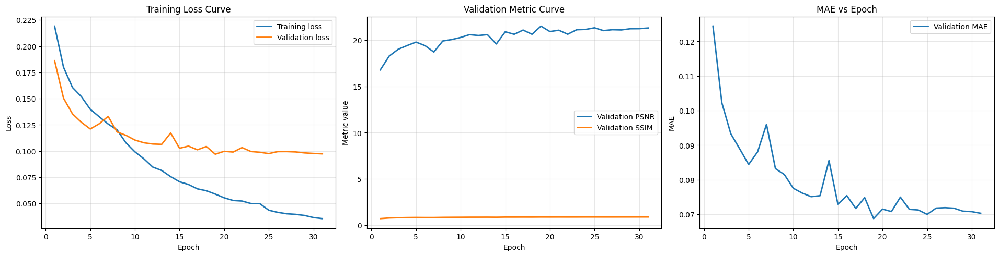

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), constrained_layout=True)
epochs = history["epoch"]
axes[0].plot(epochs, history["train_loss"], label="Training loss", linewidth=2)
axes[0].plot(epochs, history["val_loss"], label="Validation loss", linewidth=2)
axes[0].set(title="Training Loss Curve", xlabel="Epoch", ylabel="Loss")
axes[0].grid(alpha=.3); axes[0].legend()
axes[1].plot(epochs, history["val_psnr"], label="Validation PSNR", linewidth=2)
axes[1].plot(epochs, history["val_ssim"], label="Validation SSIM", linewidth=2)
axes[1].set(title="Validation Metric Curve", xlabel="Epoch", ylabel="Metric value")
axes[1].grid(alpha=.3); axes[1].legend()
axes[2].plot(epochs, history["val_mae"], label="Validation MAE", linewidth=2)
axes[2].set(title="MAE vs Epoch", xlabel="Epoch", ylabel="MAE")
axes[2].grid(alpha=.3); axes[2].legend()
plt.show()


## Test Protocol: NHD, RESIDE, and reside-6k
Every paired hazy image is dehazed and compared with its ground truth using PSNR, SSIM, MAE, and RMSE.


In [8]:
def dehaze_metrics(pred, gt):
    return {
        "PSNR": float(peak_signal_noise_ratio(gt, pred, data_range=1.0)),
        "SSIM": float(structural_similarity(gt, pred, channel_axis=-1, data_range=1.0)),
        "MAE": float(np.abs(pred.astype(np.float32) - gt.astype(np.float32)).mean()),
        "RMSE": float(np.sqrt(np.mean((pred.astype(np.float32) - gt.astype(np.float32)) ** 2))),
    }

def evaluate_dataset(model, dataset):
    records = []
    loader = make_loader(dataset)
    model.eval()
    with torch.no_grad():
        for batch in tqdm(loader, desc=f"Test {dataset.dataset_name}"):
            pred = model(batch["hazy"].to(device)).cpu()
            for i in range(pred.shape[0]):
                pred_np = pred[i].permute(1, 2, 0).numpy()
                gt_np = batch["gt"][i].permute(1, 2, 0).numpy()
                scores = dehaze_metrics(pred_np, gt_np)
                records.append({"dataset": dataset.dataset_name, "img_id": batch["img_id"][i], **scores})
    return pd.DataFrame(records)

reside_root = find_paired_root(cfg.RESIDE_ROOT, [
    "/kaggle/input/datasets/rathlavathramesh/reside/RESIDE_NHD",
    "/kaggle/input/reside-dataset-1/RESIDE_NHD/test",
    "/kaggle/input/reside/RESIDE_NHD/test",
])
reside6k_root = find_paired_root(cfg.RESIDE6K_ROOT, [
    "/kaggle/input/datasets/rathlavathramesh/reside-6k-dataset",
    "/kaggle/input/reside-6k-dataset/test",
    "/kaggle/input/reside6k-dataset/test",
])

test_datasets = {"NHD_dataset": test_dataset}
if reside_root:
    reside_dataset = PairedDehazeDataset(build_image_pairs_from_folders(os.path.join(reside_root, "hazy"), os.path.join(reside_root, "gt")), "RESIDE")
    if len(reside_dataset): test_datasets["RESIDE"] = reside_dataset
else:
    print("RESIDE not found; attach the dataset or update cfg.RESIDE_ROOT.")
if reside6k_root:
    reside6k_dataset = PairedDehazeDataset(build_image_pairs_from_folders(os.path.join(reside6k_root, "hazy"), os.path.join(reside6k_root, "gt")), "reside-6k")
    if len(reside6k_dataset): test_datasets["reside-6k"] = reside6k_dataset
else:
    print("reside-6k not found; attach the dataset or update cfg.RESIDE6K_ROOT.")

per_image_results = pd.concat([evaluate_dataset(model, ds) for ds in test_datasets.values()], ignore_index=True)
dataset_summary = per_image_results.groupby("dataset", as_index=False).agg(Images=("img_id", "count"), PSNR=("PSNR", "mean"), SSIM=("SSIM", "mean"), MAE=("MAE", "mean"), RMSE=("RMSE", "mean")).sort_values("dataset")
display(dataset_summary.style.format({"PSNR": "{:.4f}", "SSIM": "{:.4f}", "MAE": "{:.6f}", "RMSE": "{:.6f}"}))
per_image_results.to_csv(os.path.join(cfg.OUT_DIR, "ldformer_per_image_results.csv"), index=False)
dataset_summary.to_csv(os.path.join(cfg.OUT_DIR, "ldformer_dataset_summary.csv"), index=False)


Test NHD_dataset:   0%|          | 0/70 [00:00<?, ?it/s]

Test RESIDE:   0%|          | 0/200 [00:00<?, ?it/s]

Test reside-6k:   0%|          | 0/1000 [00:00<?, ?it/s]

,dataset,Images,PSNR,SSIM,MAE,RMSE
0,NHD_dataset,70,21.7510,0.8799,0.066788,0.086938
1,RESIDE,200,18.8488,0.8558,0.096215,0.124059
2,reside-6k,1000,19.9822,0.8468,0.082285,0.106395


## PSNR Comparison


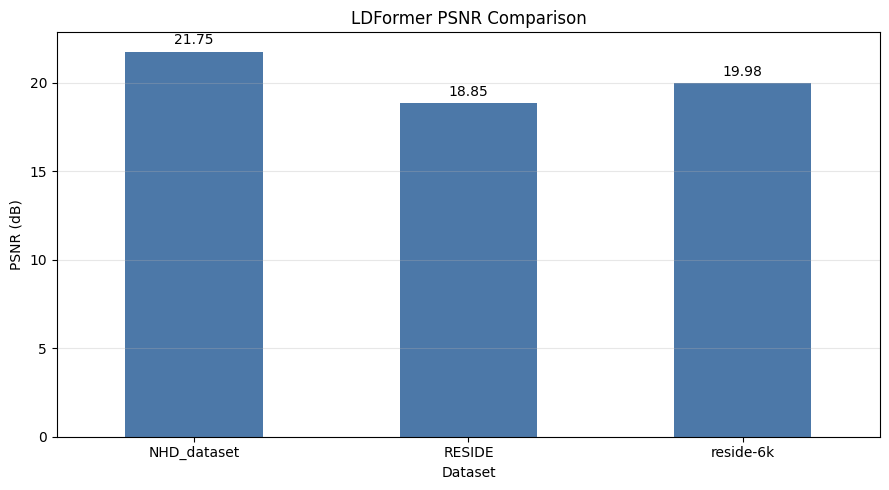

In [9]:
ax = dataset_summary.plot(x="dataset", y="PSNR", kind="bar", legend=False, figsize=(9, 5), color="#4C78A8")
ax.set(title="LDFormer PSNR Comparison", xlabel="Dataset", ylabel="PSNR (dB)")
ax.set_xticklabels(dataset_summary["dataset"], rotation=0)
ax.grid(axis="y", alpha=.3)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)
plt.tight_layout(); plt.show()


## Subjective Visual Comparison
Show input haze, ground truth, LDFormer output, and an absolute-error map for every test dataset.


NHD_dataset


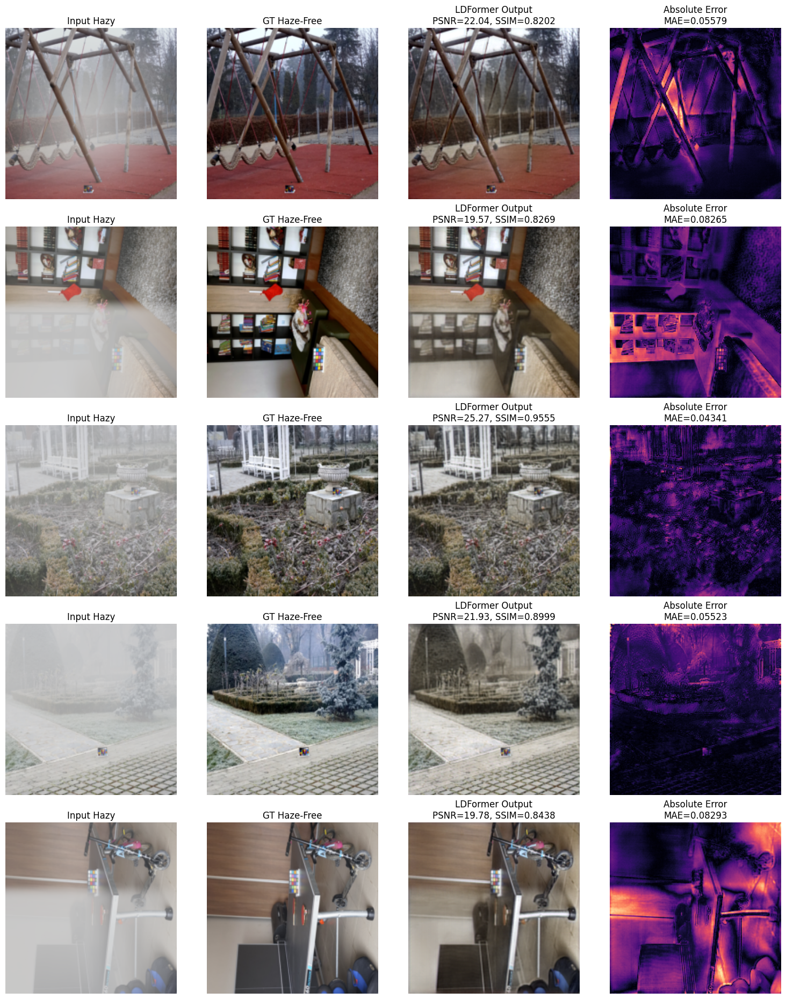

RESIDE


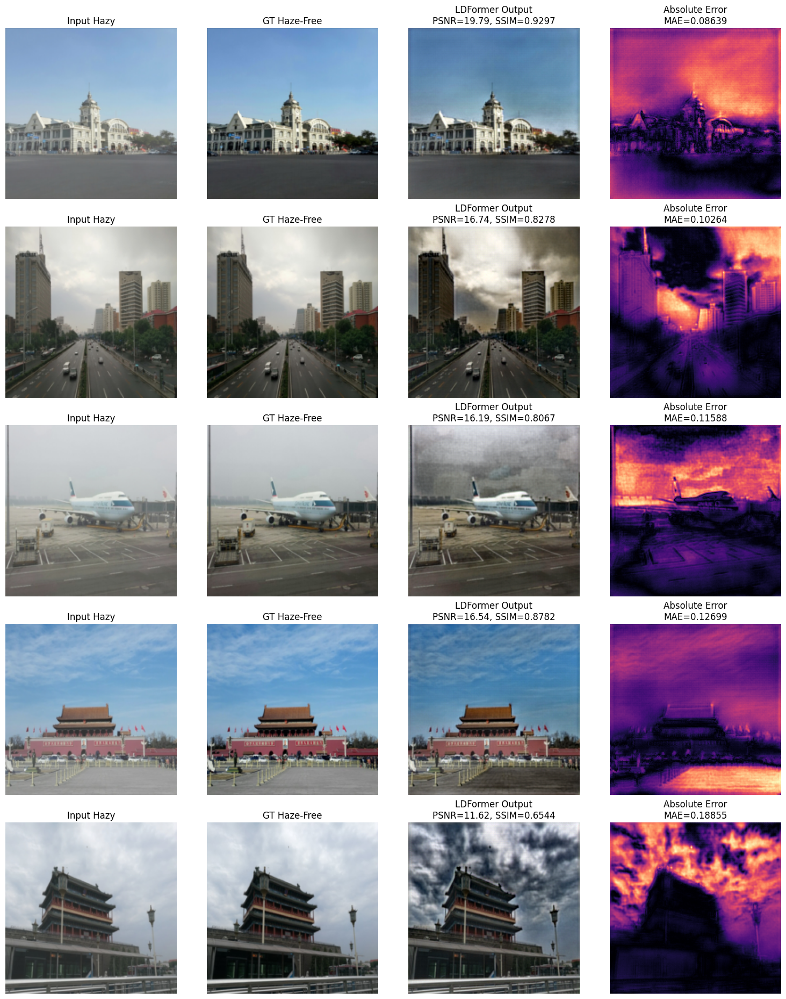

reside-6k


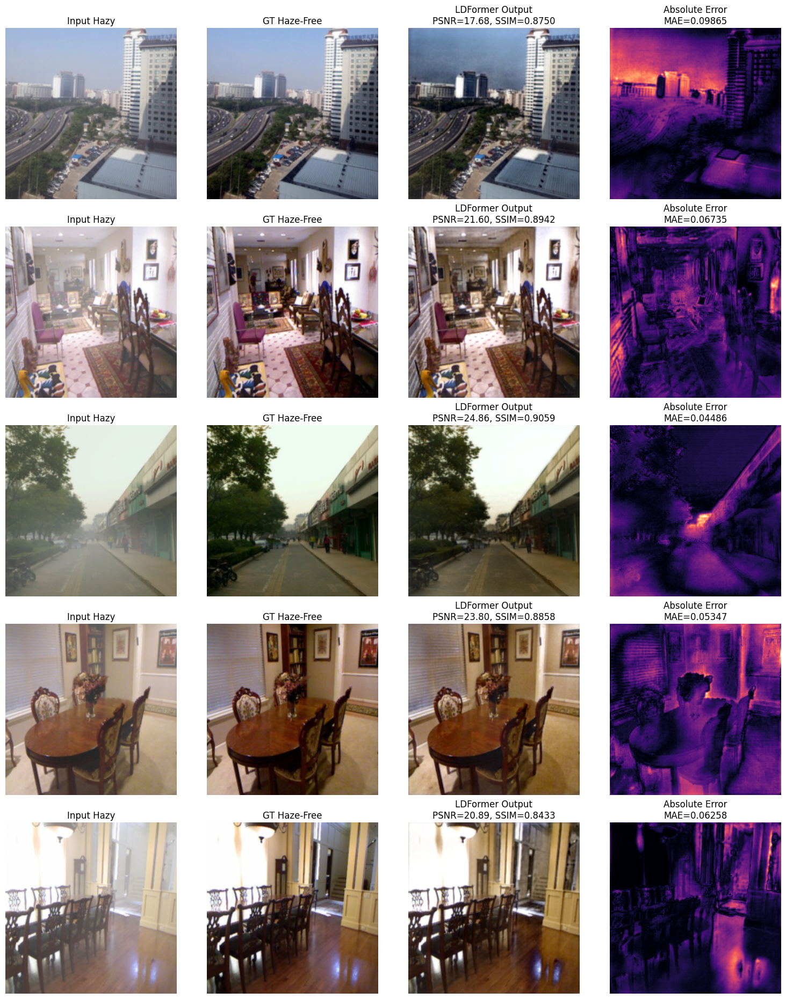

In [10]:
def show_subjective_comparison(model, dataset, n=5):
    model.eval()
    indices = random.sample(range(len(dataset)), min(n, len(dataset)))
    fig, axes = plt.subplots(len(indices), 4, figsize=(15, 3.7 * len(indices)), constrained_layout=True)
    if len(indices) == 1: axes = axes[None, :]
    with torch.no_grad():
        for row, idx in enumerate(indices):
            item = dataset[idx]
            hazy, gt = item["hazy"], item["gt"]
            pred = model(hazy.unsqueeze(0).to(device)).squeeze(0).cpu()
            hazy_np, gt_np, pred_np = [x.permute(1, 2, 0).numpy() for x in (hazy, gt, pred)]
            scores = dehaze_metrics(pred_np, gt_np)
            panels = [(hazy_np, "Input Hazy"), (gt_np, "GT Haze-Free"), (pred_np, f"LDFormer Output\nPSNR={scores['PSNR']:.2f}, SSIM={scores['SSIM']:.4f}"), (np.abs(pred_np - gt_np).mean(-1), f"Absolute Error\nMAE={scores['MAE']:.5f}")]
            for col, (image, title) in enumerate(panels):
                axes[row, col].imshow(image, cmap="magma" if col == 3 else None)
                axes[row, col].set_title(title); axes[row, col].axis("off")
    plt.show()

for name, dataset in test_datasets.items():
    print(name)
    show_subjective_comparison(model, dataset, n=5)


## Model Summary and Presentation Export


Model: LDFormer
Trainable parameters: 6,622,016


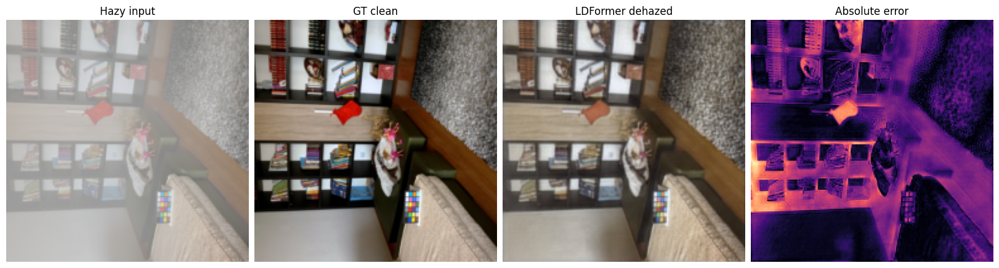

Saved: /kaggle/working/ldformer_nhd/ldformer_NHD_dataset_sample_000.png


,PSNR,SSIM,MAE,RMSE
0,20.3562,0.8469,0.0754,0.096


In [11]:
def export_presentation_sample(model, dataset, sample_index=0, output_dir=None):
    output_dir = output_dir or cfg.OUT_DIR
    os.makedirs(output_dir, exist_ok=True)
    item = dataset[sample_index]
    model.eval()
    with torch.no_grad():
        pred = model(item["hazy"].unsqueeze(0).to(device)).squeeze(0).cpu()
    hazy, gt, pred = [x.permute(1, 2, 0).numpy() for x in (item["hazy"], item["gt"], pred)]
    error = np.abs(pred - gt).mean(-1)
    scores = dehaze_metrics(pred, gt)
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), constrained_layout=True)
    for ax, image, title in zip(axes, [hazy, gt, pred, error], ["Hazy input", "GT clean", "LDFormer dehazed", "Absolute error"]):
        ax.imshow(image, cmap="magma" if title == "Absolute error" else None)
        ax.set_title(title); ax.axis("off")
    path = os.path.join(output_dir, f"ldformer_{dataset.dataset_name}_sample_{sample_index:03d}.png")
    fig.savefig(path, dpi=220, bbox_inches="tight")
    plt.show()
    print("Saved:", path)
    display(pd.DataFrame([scores]).round(4))
    return path, scores

print(f"Model: {model.__class__.__name__}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")
presentation_panel_path, presentation_sample_metrics = export_presentation_sample(model, test_dataset, sample_index=0)